In [1]:
import os
import h5py
import numpy as np
from pathlib import Path

DATA_PATH = Path("../data/modelnet40_ply_hdf5_2048")

In [2]:
h5_files = sorted(DATA_PATH.glob("*.h5"))

print("Total HDF5 files:", len(h5_files))

for file in h5_files:

    with h5py.File(file, 'r') as f:

        data = f['data'][:]
        labels = f['label'][:]

        print("\nFile:", file.name)
        print("Data shape:", data.shape)
        print("Label shape:", labels.shape)
        print("Unique labels:", len(np.unique(labels)))

Total HDF5 files: 7

File: ply_data_test0.h5
Data shape: (2048, 2048, 3)
Label shape: (2048, 1)
Unique labels: 40

File: ply_data_test1.h5
Data shape: (420, 2048, 3)
Label shape: (420, 1)
Unique labels: 40

File: ply_data_train0.h5
Data shape: (2048, 2048, 3)
Label shape: (2048, 1)
Unique labels: 40

File: ply_data_train1.h5
Data shape: (2048, 2048, 3)
Label shape: (2048, 1)
Unique labels: 40

File: ply_data_train2.h5
Data shape: (2048, 2048, 3)
Label shape: (2048, 1)
Unique labels: 40

File: ply_data_train3.h5
Data shape: (2048, 2048, 3)
Label shape: (2048, 1)
Unique labels: 40

File: ply_data_train4.h5
Data shape: (1648, 2048, 3)
Label shape: (1648, 1)
Unique labels: 40


In [3]:
for file in h5_files:

    with h5py.File(file, 'r') as f:

        data = f['data'][:]
        labels = f['label'][:]

        assert data.shape[1:] == (2048, 3)
        assert labels.shape == (data.shape[0], 1)

        assert np.isfinite(data).all()
        assert np.isfinite(labels).all()

        assert labels.min() >= 0
        assert labels.max() < 40

print("Dataset verification successful!")

Dataset verification successful!


In [4]:
with open(DATA_PATH / "shape_names.txt", "r") as f:
    shape_names = [line.strip() for line in f]

print("Total categories:", len(shape_names))

for i, name in enumerate(shape_names):
    print(i, name)
    

Total categories: 40
0 airplane
1 bathtub
2 bed
3 bench
4 bookshelf
5 bottle
6 bowl
7 car
8 chair
9 cone
10 cup
11 curtain
12 desk
13 door
14 dresser
15 flower_pot
16 glass_box
17 guitar
18 keyboard
19 lamp
20 laptop
21 mantel
22 monitor
23 night_stand
24 person
25 piano
26 plant
27 radio
28 range_hood
29 sink
30 sofa
31 stairs
32 stool
33 table
34 tent
35 toilet
36 tv_stand
37 vase
38 wardrobe
39 xbox


In [5]:
import h5py
import numpy as np

# Load training data
train_files = sorted(DATA_PATH.glob("ply_data_train*.h5"))

X_train = []
y_train = []

for file in train_files:
    with h5py.File(file, 'r') as f:
        X_train.append(f['data'][:])
        y_train.append(f['label'][:])

X_train = np.concatenate(X_train, axis=0)
y_train = np.concatenate(y_train, axis=0)


# Load testing data
test_files = sorted(DATA_PATH.glob("ply_data_test*.h5"))

X_test = []
y_test = []

for file in test_files:
    with h5py.File(file, 'r') as f:
        X_test.append(f['data'][:])
        y_test.append(f['label'][:])

X_test = np.concatenate(X_test, axis=0)
y_test = np.concatenate(y_test, axis=0)

In [6]:
print("Training data:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing data:", X_test.shape)
print("Testing labels:", y_test.shape)

print("Number of classes:", len(shape_names))

Training data: (9840, 2048, 3)
Training labels: (9840, 1)
Testing data: (2468, 2048, 3)
Testing labels: (2468, 1)
Number of classes: 40


Object category: sofa
Point cloud shape: (2048, 3)


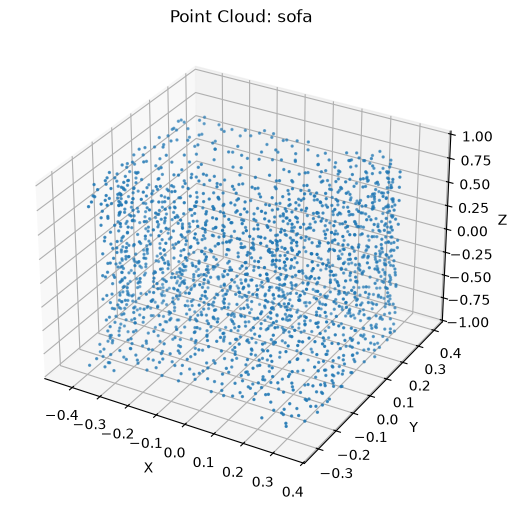

In [7]:
import matplotlib.pyplot as plt

# Select first object
points = X_train[0]

# Get its label
label = y_train[0].item()

# Get object category
class_name = shape_names[label]

print("Object category:", class_name)
print("Point cloud shape:", points.shape)

# Visualize
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    s=2
)

ax.set_title(f"Point Cloud: {class_name}")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

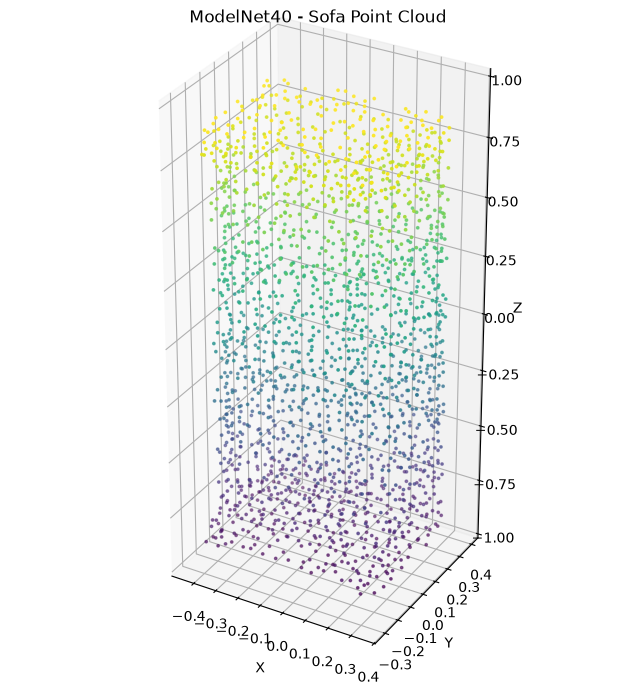

In [8]:
import matplotlib.pyplot as plt

points = X_train[0]

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    c=points[:, 2],
    cmap='viridis',
    s=3
)

ax.set_title("ModelNet40 - Sofa Point Cloud")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

# Maintain equal axis proportions
ax.set_box_aspect((
    np.ptp(points[:, 0]),
    np.ptp(points[:, 1]),
    np.ptp(points[:, 2])
))

plt.show()

In [9]:
print(X_train.shape)  # (9840, 2048, 3)
print(y_train.shape)  # (9840, 1)

print(X_test.shape)   # (2468, 2048, 3)
print(y_test.shape)   # (2468, 1)

(9840, 2048, 3)
(9840, 1)
(2468, 2048, 3)
(2468, 1)


In [10]:
import tensorflow as tf
import numpy as np

NUM_POINTS = 2048
NUM_CLASSES = 40
BATCH_SIZE = 16

# Keep all 2048 points
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

# Flatten labels
y_train = y_train.reshape(-1).astype(np.int32)
y_test = y_test.reshape(-1).astype(np.int32)

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (9840, 2048, 3) (9840,)
Testing: (2468, 2048, 3) (2468,)


In [11]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(9840)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [12]:
from tensorflow.keras import layers, Model

def tnet(inputs, k):

    # Point-wise feature extraction
    x = layers.Conv1D(64, 1, use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Global feature aggregation
    x = layers.GlobalMaxPooling1D()(x)

    # Fully connected layers
    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Predict k x k transformation matrix
    identity = np.eye(k).flatten().astype(np.float32)

    x = layers.Dense(
        k * k,
        kernel_initializer='zeros',
        bias_initializer=tf.keras.initializers.Constant(identity)
    )(x)

    transform = layers.Reshape((k, k))(x)

    return transform

In [13]:
class OrthogonalRegularizer(layers.Layer):

    def __init__(self, reg_weight=0.001, **kwargs):
        super().__init__(**kwargs)
        self.reg_weight = reg_weight

    def call(self, inputs):

        k = inputs.shape[-1]

        identity = tf.eye(k, dtype=inputs.dtype)

        product = tf.matmul(
            inputs,
            inputs,
            transpose_b=True
        )

        loss = tf.reduce_mean(
            tf.square(product - identity)
        )

        self.add_loss(self.reg_weight * loss)

        return inputs

In [14]:
def build_pointnet(num_points=2048, num_classes=40):

    inputs = layers.Input(
        shape=(num_points, 3)
    )

    # --------------------------------
    # 1. Input Transformation Network
    # --------------------------------

    input_transform = tnet(inputs, 3)

    x = layers.Dot(axes=(2, 1))(
        [inputs, input_transform]
    )

    # --------------------------------
    # 2. Shared MLP
    # --------------------------------

    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # --------------------------------
    # 3. Feature Transformation Network
    # --------------------------------

    feature_transform = tnet(x, 64)

    feature_transform = OrthogonalRegularizer()(
        feature_transform
    )

    x = layers.Dot(axes=(2, 1))(
        [x, feature_transform]
    )

    # --------------------------------
    # 4. More Shared MLP layers
    # --------------------------------

    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # --------------------------------
    # 5. Global Max Pooling
    # --------------------------------

    x = layers.GlobalMaxPooling1D()(x)

    # --------------------------------
    # 6. Classification Network
    # --------------------------------

    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.3)(x)

    # --------------------------------
    # 7. Classification Output
    # --------------------------------

    outputs = layers.Dense(
        num_classes,
        activation='softmax'
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="PointNet"
    )

    return model

In [15]:
model = build_pointnet(
    num_points=2048,
    num_classes=40
)

model.summary()

Model: "PointNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 2048, 3)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 2048, 64)  │        192 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 2048, 64)  │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 2048, 64)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 2048, 128) │      8,192 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2048, 128) │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 2048, 128) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 2048,      │    131,072 │ activation_1[0][… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2048,      │      4,096 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 2048,      │          0 │ batch_normalizat… │
│ (Activation)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1024)      │          0 │ activation_2[0][… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │    524,288 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 512)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    131,072 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 9)         │      2,313 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 3,486,129 (13.30 MB)

 Trainable params: 3,473,969 (13.25 MB)

 Non-trainable params: 12,160 (47.50 KB)

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
log_dir = "logs/pointnet"

tensorboard_callback = tf.keras.callbacks.TensorBoard(
    log_dir=log_dir,
    histogram_freq=0,
    write_graph=False,
    update_freq="epoch"
)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6
    ),

    tensorboard_callback  
]


In [19]:
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/50


/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


615/615 ━━━━━━━━━━━━━━━━━━━━ 956s 2s/step - accuracy: 0.5073 - loss: 1.8656 - val_accuracy: 0.5369 - val_loss: 1.5764 - learning_rate: 0.0010
Epoch 2/50
615/615 ━━━━━━━━━━━━━━━━━━━━ 1231s 2s/step - accuracy: 0.6712 - loss: 1.1671 - val_accuracy: 0.4615 - val_loss: 2.1132 - learning_rate: 0.0010
Epoch 3/50
615/615 ━━━━━━━━━━━━━━━━━━━━ 752s 1s/step - accuracy: 0.7222 - loss: 0.9744 - val_accuracy: 0.7196 - val_loss: 1.0164 - learning_rate: 0.0010
Epoch 4/50
615/615 ━━━━━━━━━━━━━━━━━━━━ 911s 1s/step - accuracy: 0.7500 - loss: 0.8606 - val_accuracy: 0.7512 - val_loss: 0.8430 - learning_rate: 0.0010
Epoch 5/50
615/615 ━━━━━━━━━━━━━━━━━━━━ 1184s 2s/step - accuracy: 0.7669 - loss: 0.7910 - val_accuracy: 0.6714 - val_loss: 1.1097 - learning_rate: 0.0010
Epoch 6/50
615/615 ━━━━━━━━━━━━━━━━━━━━ 867s 1s/step - accuracy: 0.7849 - loss: 0.7310 - val_accuracy: 0.7050 - val_loss: 0.9989 - learning_rate: 0.0010
Epoch 7/50
615/615 ━━━━━━━━━━━━━━━━━━━━ 888s 1s/step - accuracy: 0.7950 - loss: 0.6918 - va

In [20]:
# Save the complete trained model
model.save("pointnet_model.keras")

print("PointNet model saved successfully!")

PointNet model saved successfully!


In [21]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

155/155 ━━━━━━━━━━━━━━━━━━━━ 22s 139ms/step - accuracy: 0.8930 - loss: 0.4096
Test Loss: 0.4096185266971588
Test Accuracy: 0.8930308222770691


In [23]:
sample = X_test[2:3]  # Select a single sample for prediction

prediction = model.predict(sample)

predicted_class = np.argmax(prediction[0])

actual_class = y_test[2]

print("Predicted:", shape_names[predicted_class])
print("Actual:", shape_names[actual_class])
print("Confidence:", np.max(prediction[0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Predicted: bed
Actual: bed
Confidence: 0.99997246
